<a href="https://colab.research.google.com/github/Alyaputri11/Flower-Classification-CNN/blob/main/CODE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive.zip


In [3]:

import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/flowers_dataset')

print("Dataset berhasil diekstrak!")

os.listdir('/content/flowers_dataset')


Dataset berhasil diekstrak!


['flowers']

In [4]:

import os

for root, dirs, files in os.walk('/content/flowers_dataset'):
    level = root.replace('/content/flowers_dataset', '').count(os.sep)
    indent = ' ' * 4 * level
    print(f'{indent}{os.path.basename(root)}/')


flowers_dataset/
    flowers/
        sunflower/
        dandelion/
        tulip/
        daisy/
        rose/


In [5]:

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow Version: 2.21.0
GPU Available: []


In [9]:

dataset_path = '/content/flowers_dataset/flowers'

img_size = (180, 180)
batch_size = 32

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_dataset.class_names

print("Kategori bunga:", class_names)


Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Kategori bunga: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


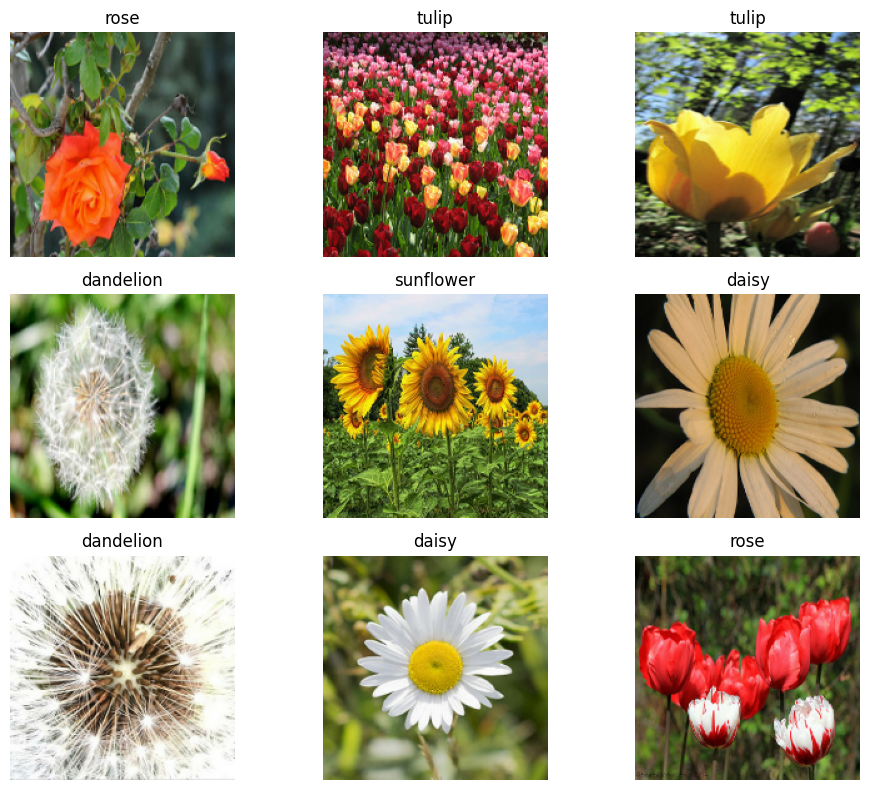

In [10]:

plt.figure(figsize=(10, 8))

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [11]:

normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Normalisasi dataset berhasil!")


Normalisasi dataset berhasil!


In [12]:

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(180, 180, 3)),

    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(5, activation='softmax')
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,621 (25.36 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model berhasil di-compile!")


Model berhasil di-compile!


In [15]:

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20
)


Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 253s 2s/step - accuracy: 0.7455 - loss: 0.6533 - val_accuracy: 0.6698 - val_loss: 0.9154
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 249s 2s/step - accuracy: 0.7991 - loss: 0.5226 - val_accuracy: 0.6860 - val_loss: 0.9414
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.8489 - loss: 0.4007 - val_accuracy: 0.6790 - val_loss: 1.0428
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.8735 - loss: 0.3510 - val_accuracy: 0.7022 - val_loss: 1.1020
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 248s 2s/step - accuracy: 0.9071 - loss: 0.2629 - val_accuracy: 0.6929 - val_loss: 1.1526
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.9071 - loss: 0.2512 - val_accuracy: 0.6837 - val_loss: 1.2417
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 264s 2s/step - accuracy: 0.9320 - loss: 0.1857 - val_accuracy: 0.7068 - val_loss: 1.3573
Epoch 8/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.9493 - loss: 0.1473 - val_accu

In [16]:
model.save('/content/flower_classification_cnn.keras')

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [18]:

import os

model_path = '/content/flower_classification_cnn.keras'

if os.path.exists(model_path):
    print("MODEL AMAN!")
    print("Ukuran file:", os.path.getsize(model_path) / (1024*1024), "MB")
else:
    print("File model tidak ditemukan!")


MODEL AMAN!
Ukuran file: 76.1213436126709 MB


In [19]:

from google.colab import files

files.download('/content/flower_classification_cnn.keras')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

if 'history' in globals():
    print("Training sudah dilakukan!")
    print("Jumlah epoch:", len(history.history['accuracy']))
    print("Training Accuracy terakhir:",
          history.history['accuracy'][-1])
    print("Validation Accuracy terakhir:",
          history.history['val_accuracy'][-1])
else:
    print("Training belum dilakukan!")


Training sudah dilakukan!
Jumlah epoch: 20
Training Accuracy terakhir: 0.9791545867919922
Validation Accuracy terakhir: 0.673232913017273


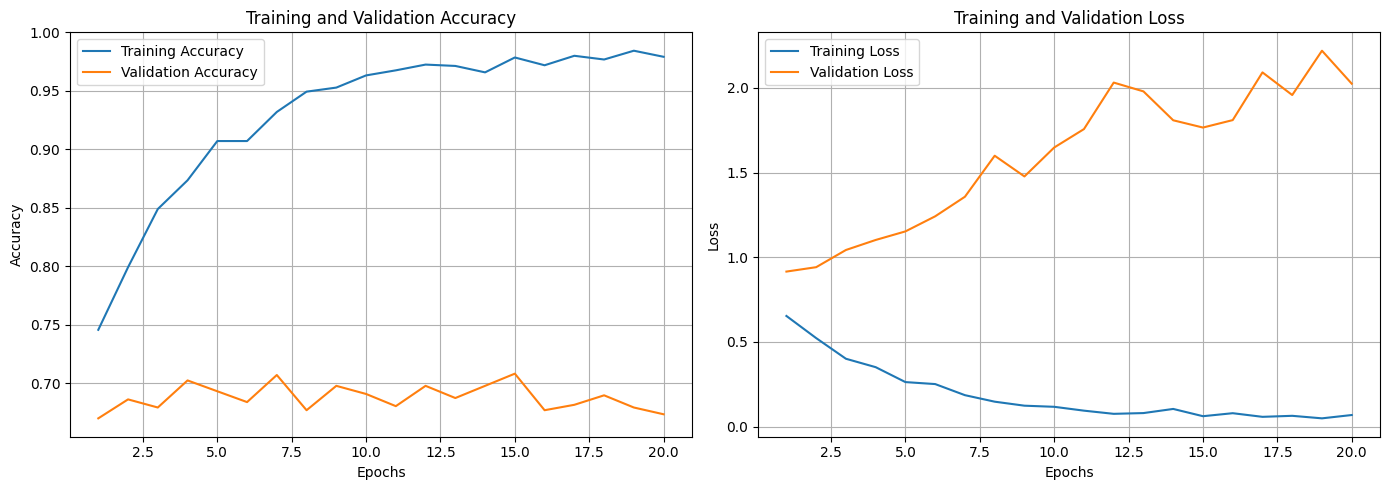

In [21]:

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [22]:

val_loss, val_accuracy = model.evaluate(validation_dataset)

print("Evaluation Results")
print("-------------------------")
print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")


27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 608ms/step - accuracy: 0.6732 - loss: 2.0247
Evaluation Results
-------------------------
Validation Loss     : 2.0247
Validation Accuracy : 67.32%


<Figure size 900x700 with 0 Axes>

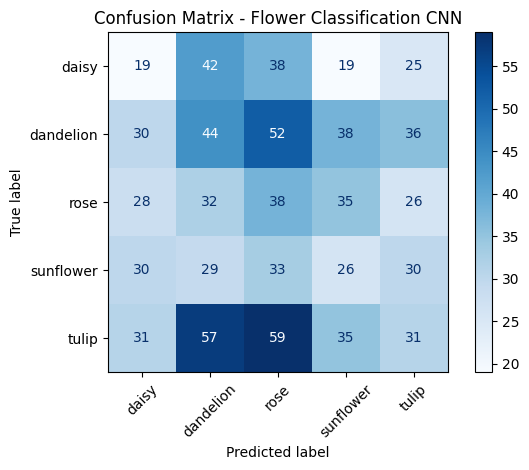

In [23]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

y_true = np.concatenate([
    labels.numpy() for images, labels in validation_dataset
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in validation_dataset
])

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Flower Classification CNN')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [24]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

       daisy       0.14      0.13      0.14       143
   dandelion       0.22      0.22      0.22       200
        rose       0.17      0.24      0.20       159
   sunflower       0.17      0.18      0.17       148
       tulip       0.21      0.15      0.17       213

    accuracy                           0.18       863
   macro avg       0.18      0.18      0.18       863
weighted avg       0.19      0.18      0.18       863



In [25]:

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    shuffle=False
)

# Normalisasi gambar
validation_dataset = validation_dataset.map(
    lambda x, y: (x / 255.0, y)
)

print("Validation dataset berhasil diperbarui!")


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Validation dataset berhasil diperbarui!


In [26]:

y_true = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset
])

y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, labels in validation_dataset
])

print("Jumlah label asli:", len(y_true))
print("Jumlah prediksi:", len(y_pred))


Jumlah label asli: 863
Jumlah prediksi: 863


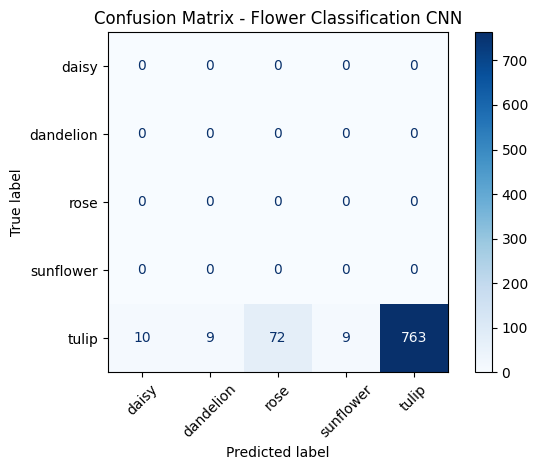

In [27]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Flower Classification CNN')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [28]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00         0
   dandelion       0.00      0.00      0.00         0
        rose       0.00      0.00      0.00         0
   sunflower       0.00      0.00      0.00         0
       tulip       1.00      0.88      0.94       863

    accuracy                           0.88       863
   macro avg       0.20      0.18      0.19       863
weighted avg       1.00      0.88      0.94       863



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [29]:

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    shuffle=False
)

# Normalisasi menggunakan Rescaling
normalization_layer = tf.keras.layers.Rescaling(1./255)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Class names:", validation_dataset.class_names if hasattr(validation_dataset, 'class_names') else class_names)


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Class names: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [30]:

from collections import Counter

y_true = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset
])

print("Distribusi label aktual:")

for index, count in sorted(Counter(y_true).items()):
    print(f"{class_names[index]}: {count}")

print("Total data:", len(y_true))


Distribusi label aktual:
tulip: 863
Total data: 863


In [31]:

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(180, 180),
    batch_size=32,
    shuffle=True
)

normalization_layer = tf.keras.layers.Rescaling(1./255)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

print("Validation dataset berhasil diperbaiki!")


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Validation dataset berhasil diperbaiki!


In [32]:

from collections import Counter
import numpy as np

y_true = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset
])

print("Distribusi label aktual:")

for index, count in sorted(Counter(y_true).items()):
    print(f"{class_names[index]}: {count}")

print("Total data:", len(y_true))


Distribusi label aktual:
daisy: 143
dandelion: 200
rose: 159
sunflower: 148
tulip: 213
Total data: 863


In [33]:

y_true = []
y_pred = []

for images, labels in validation_dataset:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Jumlah label:", len(y_true))
print("Jumlah prediksi:", len(y_pred))


Jumlah label: 863
Jumlah prediksi: 863


In [34]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))


              precision    recall  f1-score   support

       daisy       0.65      0.63      0.64       143
   dandelion       0.75      0.77      0.76       200
        rose       0.48      0.67      0.56       159
   sunflower       0.76      0.79      0.78       148
       tulip       0.77      0.54      0.63       213

    accuracy                           0.67       863
   macro avg       0.68      0.68      0.67       863
weighted avg       0.69      0.67      0.68       863



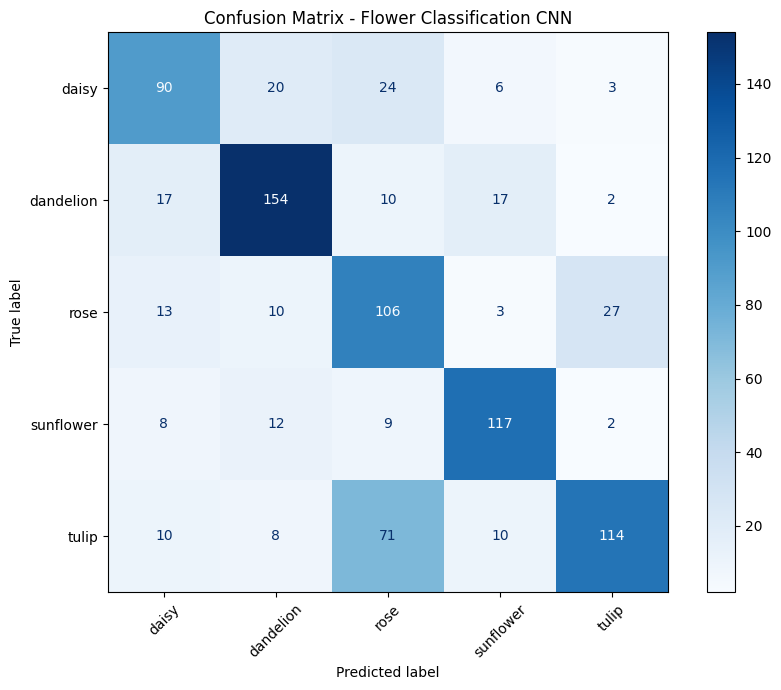

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap='Blues',
    values_format='d',
    ax=ax
)

plt.title('Confusion Matrix - Flower Classification CNN')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:

from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))


              precision    recall  f1-score   support

       daisy       0.65      0.63      0.64       143
   dandelion       0.75      0.77      0.76       200
        rose       0.48      0.67      0.56       159
   sunflower       0.76      0.79      0.78       148
       tulip       0.77      0.54      0.63       213

    accuracy                           0.67       863
   macro avg       0.68      0.68      0.67       863
weighted avg       0.69      0.67      0.68       863



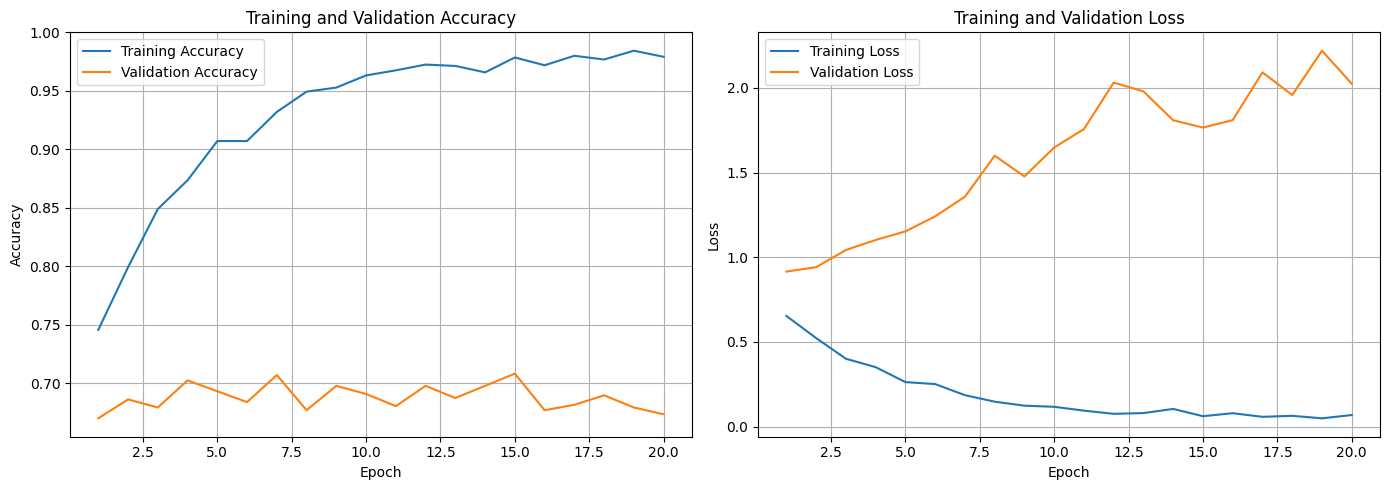

In [37]:

import matplotlib.pyplot as plt

# Mengambil riwayat training
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Grafik Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [38]:

# Melihat arsitektur model CNN saat ini

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,942,865 (76.08 MB)

 Trainable params: 6,647,621 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,295,244 (50.72 MB)

In [39]:

# Melihat konfigurasi optimizer

print("Optimizer:", model.optimizer)

print("Learning Rate:",
      model.optimizer.learning_rate.numpy())


Optimizer: <keras.src.optimizers.adam.Adam object at 0x7cd8703f70e0>
Learning Rate: 0.001


In [40]:

# Mengecek konfigurasi setiap layer
for layer in model.layers:
    print(layer.name, layer.get_config())

# Mengecek optimizer dan learning rate
print("\nOptimizer:", model.optimizer)
print("Learning Rate:",
      model.optimizer.learning_rate.numpy())


conv2d {'name': 'conv2d', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'filters': 32, 'kernel_size': (3, 3), 'strides': (1, 1), 'padding': 'valid', 'data_format': 'channels_last', 'dilation_rate': (1, 1), 'groups': 1, 'activation': 'relu', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'activity_regularizer': None, 'kernel_constraint': None, 'bias_constraint': None}
max_pooling2d {'name': 'max_pooling2d', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'pool_size': (2, 2), 'padding': 'valid', 'strides': (2, 2), 'data_format': 'channels_last

In [42]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
ConfusionMatrixDisplay   type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
Counter                  type                      <class 'collections.Counter'>
acc                      list                      n=20
ax                       Axes                      Axes(0.185352,0.146718;0.622182x0.799949)
batch_size               int                       32
class_names              list                      n=5
classification_report    function                  <function classification_<...>report at 0x7cd85b2599e0>
cm                       ndarray                   5x5: 25 elems, type `int64`, 200 bytes
confusion_matrix         function                  <function confusion_matrix at 0x7cd85b2587c0>
count                    int                       213
dataset_path             str                       /content/flowers_dataset/flowers

In [43]:
print("Train dataset:")
print(train_dataset.element_spec)

print("\nValidation dataset:")
print(validation_dataset.element_spec)

Train dataset:
(TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))

Validation dataset:
(TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [44]:
print("Jumlah kelas:", len(class_names))
print("Nama kelas:", class_names)

print("\nUkuran input model:", model.input_shape)
print("Ukuran output model:", model.output_shape)

Jumlah kelas: 5
Nama kelas: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']

Ukuran input model: (None, 180, 180, 3)
Ukuran output model: (None, 5)


In [45]:
print("===== DATASET INFORMATION =====")

print("\nTrain dataset:")
print(train_dataset.element_spec)

print("\nValidation dataset:")
print(validation_dataset.element_spec)

print("\n===== MODEL INFORMATION =====")

print("Jumlah kelas:", len(class_names))
print("Nama kelas:", class_names)

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

===== DATASET INFORMATION =====

Train dataset:
(TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))

Validation dataset:
(TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))

===== MODEL INFORMATION =====
Jumlah kelas: 5
Nama kelas: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Input shape: (None, 180, 180, 3)
Output shape: (None, 5)


In [46]:

# ==========================================
# CNN MODEL 2 - GLOBAL AVERAGE POOLING
# ==========================================

from tensorflow.keras import layers, models

model_2 = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Global Average Pooling
    layers.GlobalAveragePooling2D(),

    # Fully Connected Layer
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    # Output Layer
    layers.Dense(5, activation='softmax')
])

# Compile Model
model_2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Model Summary
model_2.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [47]:

# ==========================================
# TRAINING CNN MODEL 2
# ==========================================

epochs = 20

history_2 = model_2.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=epochs
)


Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 240s 2s/step - accuracy: 0.3691 - loss: 1.3996 - val_accuracy: 0.4693 - val_loss: 1.2308
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 235s 2s/step - accuracy: 0.4453 - loss: 1.2389 - val_accuracy: 0.4820 - val_loss: 1.1585
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 229s 2s/step - accuracy: 0.4812 - loss: 1.1859 - val_accuracy: 0.5087 - val_loss: 1.1444
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 260s 2s/step - accuracy: 0.5226 - loss: 1.1296 - val_accuracy: 0.5608 - val_loss: 1.0535
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 228s 2s/step - accuracy: 0.5689 - loss: 1.0705 - val_accuracy: 0.5701 - val_loss: 1.0343
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.5880 - loss: 1.0305 - val_accuracy: 0.6118 - val_loss: 0.9316
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 254s 2s/step - accuracy: 0.6060 - loss: 0.9917 - val_accuracy: 0.6280 - val_loss: 0.9225
Epoch 8/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 229s 2s/step - accuracy: 0.6222 - loss: 0.9615 - val_accu

In [2]:

from tensorflow.keras import layers, models

model_2 = models.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(5, activation='softmax')
])

model_2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_2.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
%whos

Variable   Type          Data/Info
----------------------------------
layers     module        <module 'keras._tf_keras.<...>eras/layers/__init__.py'>
model_2    Sequential    <Sequential name=sequential, built=True>
models     module        <module 'keras.models' fr<...>eras/models/__init__.py'>


In [6]:
import os

dataset_path = '/content/flowers_dataset/flowers'

print("Folder tersedia:", os.path.exists(dataset_path))

if os.path.exists(dataset_path):
    print("Isi folder:", os.listdir(dataset_path))

Folder tersedia: False


In [7]:
import os

print("ZIP tersedia:",
      os.path.exists('/content/archive.zip'))

print("Model 1 tersedia:",
      os.path.exists('/content/flower_classification_cnn.keras'))

print("Isi folder /content:")
print(os.listdir('/content'))

ZIP tersedia: False
Model 1 tersedia: False
Isi folder /content:
['.config', 'flower_classification_cnn_v2.keras', 'sample_data']


In [8]:
from google.colab import files

files.download('/content/flower_classification_cnn_v2.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [10]:
import zipfile
import os

zip_file = '/content/archive.zip'
extract_path = '/content/flowers_dataset'

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")
print("Isi folder:", os.listdir(extract_path))

Dataset berhasil diekstrak!
Isi folder: ['flowers']


In [11]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)

    if level <= 2:
        indent = ' ' * 4 * level
        print(f"{indent}{os.path.basename(root)}/")

flowers_dataset/
    flowers/
        rose/
        tulip/
        daisy/
        dandelion/
        sunflower/


In [12]:

import tensorflow as tf

dataset_path = '/content/flowers_dataset/flowers'

img_size = (180, 180)
batch_size = 32
seed = 42

train_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='training',
    seed=seed,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int'
)

validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='validation',
    seed=seed,
    image_size=img_size,
    batch_size=batch_size,
    label_mode='int'
)

class_names = train_dataset.class_names

print("Nama kelas:", class_names)
print("Train dataset:", train_dataset.element_spec)
print("Validation dataset:", validation_dataset.element_spec)


Found 4317 files belonging to 5 classes.
Using 3454 files for training.
Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Nama kelas: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Train dataset: (TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))
Validation dataset: (TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))


In [13]:
model_2 = tf.keras.models.load_model(
    '/content/flower_classification_cnn_v2.keras'
)

model_2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 331,217 (1.26 MB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 220,812 (862.55 KB)

In [14]:
print("Jumlah data training:",
      tf.data.experimental.cardinality(train_dataset).numpy() * batch_size)

print("Jumlah batch validation:",
      tf.data.experimental.cardinality(validation_dataset).numpy())

print("Jumlah data validation:",
      sum(1 for _ in validation_dataset))

Jumlah data training: 3456
Jumlah batch validation: 27
Jumlah data validation: 27


In [15]:
print("Status model:", model_2.built)

print("\nContoh prediksi sebelum training:")
for images, labels in validation_dataset.take(1):
    predictions = model_2.predict(images[:5], verbose=0)

    for i in range(5):
        predicted_class = class_names[predictions[i].argmax()]
        actual_class = class_names[labels[i].numpy()]

        print(
            f"Actual: {actual_class} | "
            f"Predicted: {predicted_class}"
        )

Status model: True

Contoh prediksi sebelum training:
Actual: tulip | Predicted: tulip
Actual: dandelion | Predicted: tulip
Actual: sunflower | Predicted: tulip
Actual: daisy | Predicted: tulip
Actual: dandelion | Predicted: tulip


In [16]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
history_2 = model_2.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=20
)

Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 259s 2s/step - accuracy: 0.3697 - loss: 2.2520 - val_accuracy: 0.4739 - val_loss: 1.2100
Epoch 2/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - accuracy: 0.5032 - loss: 1.2266 - val_accuracy: 0.5701 - val_loss: 1.1013
Epoch 3/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 257s 2s/step - accuracy: 0.5356 - loss: 1.1698 - val_accuracy: 0.5585 - val_loss: 1.0666
Epoch 4/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.5869 - loss: 1.0620 - val_accuracy: 0.5794 - val_loss: 1.0413
Epoch 5/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 263s 2s/step - accuracy: 0.5918 - loss: 1.0398 - val_accuracy: 0.5736 - val_loss: 1.0202
Epoch 6/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 256s 2s/step - accuracy: 0.6306 - loss: 0.9920 - val_accuracy: 0.6419 - val_loss: 0.9025
Epoch 7/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 265s 2s/step - accuracy: 0.6532 - loss: 0.9370 - val_accuracy: 0.6501 - val_loss: 0.9105
Epoch 8/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 226s 2s/step - accuracy: 0.6549 - loss: 0.9108 - val_accu

In [18]:
model_2.save('/content/flower_classification_cnn_v2.keras')

print("Model 2 berhasil disimpan!")

Model 2 berhasil disimpan!


In [19]:
# Evaluasi Model 2
val_loss_2, val_accuracy_2 = model_2.evaluate(
    validation_dataset,
    verbose=1
)

print(f"\nModel 2 Validation Accuracy: {val_accuracy_2 * 100:.2f}%")
print(f"Model 2 Validation Loss: {val_loss_2:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 18s 635ms/step - accuracy: 0.7103 - loss: 0.7316

Model 2 Validation Accuracy: 71.03%
Model 2 Validation Loss: 0.7316


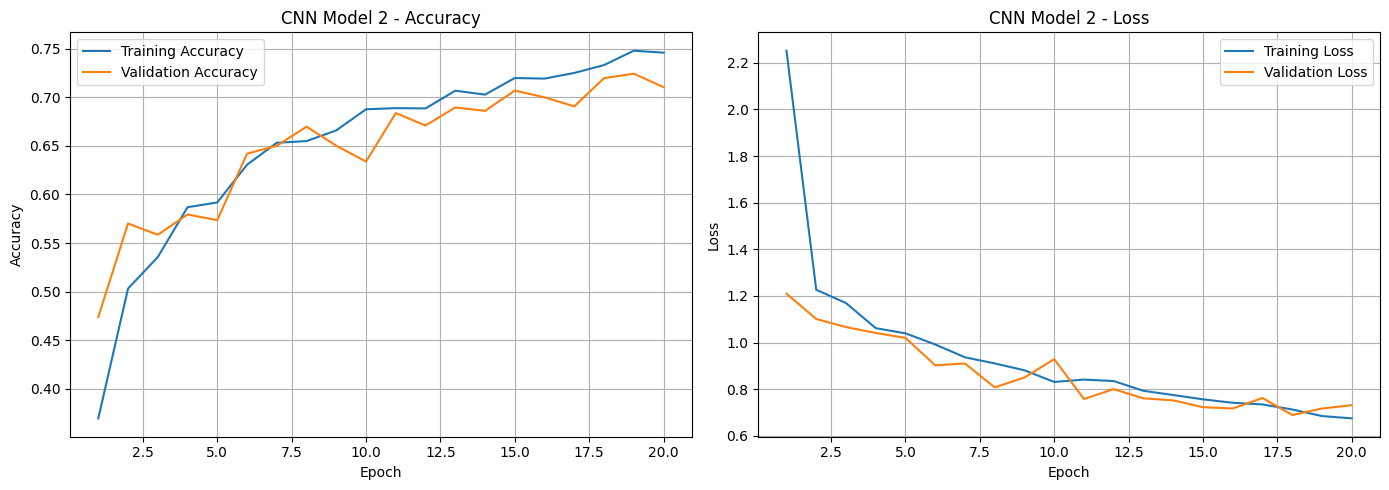

In [20]:
import matplotlib.pyplot as plt

acc_2 = history_2.history['accuracy']
val_acc_2 = history_2.history['val_accuracy']

loss_2 = history_2.history['loss']
val_loss_2 = history_2.history['val_loss']

epochs_range = range(1, len(acc_2) + 1)

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc_2, label='Training Accuracy')
plt.plot(epochs_range, val_acc_2, label='Validation Accuracy')
plt.title('CNN Model 2 - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_2, label='Training Loss')
plt.plot(epochs_range, val_loss_2, label='Validation Loss')
plt.title('CNN Model 2 - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [21]:
import numpy as np
from sklearn.metrics import classification_report

y_true_2 = np.concatenate([
    labels.numpy() for images, labels in validation_dataset
])

y_pred_2 = np.argmax(
    model_2.predict(validation_dataset),
    axis=1
)

print(classification_report(
    y_true_2,
    y_pred_2,
    target_names=class_names
))

27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 579ms/step
              precision    recall  f1-score   support

       daisy       0.13      0.13      0.13       144
   dandelion       0.23      0.19      0.21       206
        rose       0.16      0.23      0.19       137
   sunflower       0.22      0.23      0.22       172
       tulip       0.22      0.19      0.20       204

    accuracy                           0.19       863
   macro avg       0.19      0.19      0.19       863
weighted avg       0.20      0.19      0.19       863



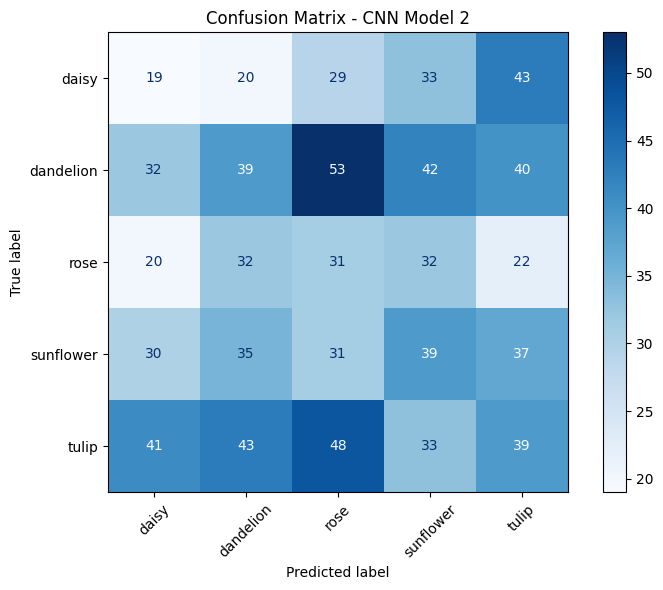

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_2 = confusion_matrix(y_true_2, y_pred_2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_2,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap='Blues',
    ax=ax,
    xticks_rotation=45
)

plt.title('Confusion Matrix - CNN Model 2')
plt.tight_layout()
plt.show()

In [23]:

# Membuat validation dataset tanpa shuffle

validation_dataset_eval = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=(180, 180),
    batch_size=32,
    label_mode='int',
    shuffle=False
)

print("Validation dataset siap!")


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Validation dataset siap!


In [24]:

from sklearn.metrics import classification_report
import numpy as np

# Evaluasi model
val_loss_2, val_accuracy_2 = model_2.evaluate(
    validation_dataset_eval,
    verbose=1
)

# Ambil label aktual
y_true_2 = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset_eval
])

# Prediksi model
predictions_2 = model_2.predict(validation_dataset_eval)

y_pred_2 = np.argmax(predictions_2, axis=1)

# Classification report
print("\nCLASSIFICATION REPORT - MODEL 2")

print(classification_report(
    y_true_2,
    y_pred_2,
    target_names=class_names
))

print(f"Validation Accuracy: {val_accuracy_2 * 100:.2f}%")
print(f"Validation Loss: {val_loss_2:.4f}")


27/27 ━━━━━━━━━━━━━━━━━━━━ 16s 599ms/step - accuracy: 0.6628 - loss: 0.6235
27/27 ━━━━━━━━━━━━━━━━━━━━ 15s 559ms/step

CLASSIFICATION REPORT - MODEL 2
              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00         0
   dandelion       0.00      0.00      0.00         0
        rose       0.00      0.00      0.00         0
   sunflower       0.00      0.00      0.00         0
       tulip       1.00      0.66      0.80       863

    accuracy                           0.66       863
   macro avg       0.20      0.13      0.16       863
weighted avg       1.00      0.66      0.80       863

Validation Accuracy: 66.28%
Validation Loss: 0.6235


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


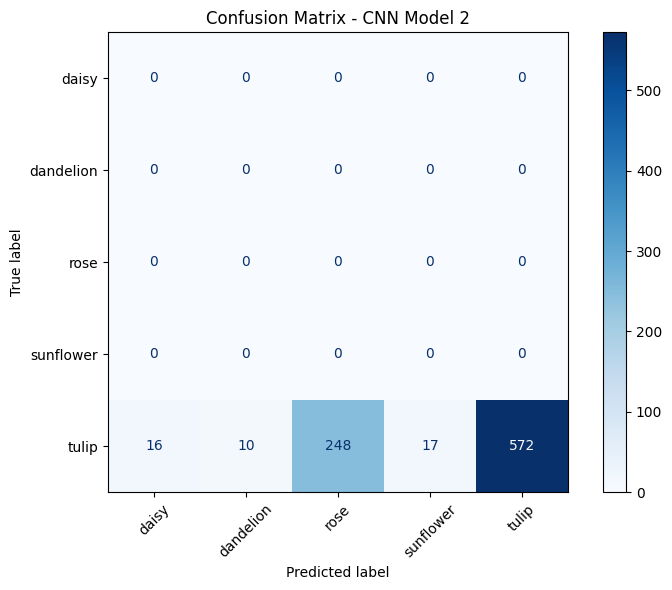

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_2 = confusion_matrix(y_true_2, y_pred_2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_2,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 6))

disp.plot(
    cmap='Blues',
    ax=ax,
    xticks_rotation=45
)

plt.title('Confusion Matrix - CNN Model 2')
plt.tight_layout()
plt.show()

In [26]:
import numpy as np
from collections import Counter

y_true_2 = np.concatenate([
    labels.numpy() for images, labels in validation_dataset_eval
])

print("Class Names:", class_names)
print("Distribusi Label:", Counter(y_true_2))
print("Unique Labels:", np.unique(y_true_2))

Class Names: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Distribusi Label: Counter({np.int32(4): 863})
Unique Labels: [4]


In [27]:
from sklearn.metrics import classification_report
import numpy as np

predictions_2 = model_2.predict(validation_dataset_eval)
y_pred_2 = np.argmax(predictions_2, axis=1)

print("CLASSIFICATION REPORT - MODEL 2")
print(classification_report(
    y_true_2,
    y_pred_2,
    labels=[0, 1, 2, 3, 4],
    target_names=class_names,
    zero_division=0
))

27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 612ms/step
CLASSIFICATION REPORT - MODEL 2
              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00         0
   dandelion       0.00      0.00      0.00         0
        rose       0.00      0.00      0.00         0
   sunflower       0.00      0.00      0.00         0
       tulip       1.00      0.66      0.80       863

    accuracy                           0.66       863
   macro avg       0.20      0.13      0.16       863
weighted avg       1.00      0.66      0.80       863



In [28]:
validation_dataset_eval = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=(180, 180),
    batch_size=32,
    label_mode='int',
    shuffle=False
)

print(validation_dataset_eval.class_names)

Found 4317 files belonging to 5 classes.
Using 863 files for validation.
['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']


In [29]:

import numpy as np
from collections import Counter

y_true_2 = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset_eval
])

print("Class Names:", validation_dataset_eval.class_names)
print("Distribusi Label:", Counter(y_true_2))
print("Unique Labels:", np.unique(y_true_2))


Class Names: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Distribusi Label: Counter({np.int32(4): 863})
Unique Labels: [4]


In [30]:

import os

print("Dataset Path:", dataset_path)
print("\nIsi folder dataset:")

for item in os.listdir(dataset_path):
    path = os.path.join(dataset_path, item)

    if os.path.isdir(path):
        print(f"\n{item}:")
        print("Jumlah file:", len(os.listdir(path)))


Dataset Path: /content/flowers_dataset/flowers

Isi folder dataset:

rose:
Jumlah file: 784

tulip:
Jumlah file: 984

daisy:
Jumlah file: 764

dandelion:
Jumlah file: 1052

sunflower:
Jumlah file: 733


In [31]:

import tensorflow as tf
import numpy as np
from collections import Counter

validation_dataset_eval = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

y_true_2 = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset_eval
])

print("Class Names:", validation_dataset_eval.class_names)
print("Distribusi Label:", Counter(y_true_2))
print("Unique Labels:", np.unique(y_true_2))


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Class Names: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Distribusi Label: Counter({np.int32(4): 863})
Unique Labels: [4]


In [32]:

validation_dataset_eval = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int",
    shuffle=True
)

y_true_2 = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset_eval
])

print("Class Names:", validation_dataset_eval.class_names)
print("Distribusi Label:", Counter(y_true_2))
print("Unique Labels:", np.unique(y_true_2))


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
Class Names: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Distribusi Label: Counter({np.int32(1): 206, np.int32(4): 204, np.int32(3): 172, np.int32(0): 144, np.int32(2): 137})
Unique Labels: [0 1 2 3 4]


In [33]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Prediksi Model 2
y_true_2 = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset_eval
])

predictions_2 = model_2.predict(validation_dataset_eval)

y_pred_2 = np.argmax(predictions_2, axis=1)

# Classification Report
print("CLASSIFICATION REPORT - MODEL 2")

print(classification_report(
    y_true_2,
    y_pred_2,
    labels=[0, 1, 2, 3, 4],
    target_names=validation_dataset_eval.class_names,
    zero_division=0
))

# Confusion Matrix
cm_2 = confusion_matrix(
    y_true_2,
    y_pred_2,
    labels=[0, 1, 2, 3, 4]
)

print("CONFUSION MATRIX - MODEL 2")
print(cm_2)


27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 594ms/step
CLASSIFICATION REPORT - MODEL 2
              precision    recall  f1-score   support

       daisy       0.12      0.12      0.12       144
   dandelion       0.28      0.23      0.25       206
        rose       0.15      0.21      0.18       137
   sunflower       0.17      0.18      0.18       172
       tulip       0.26      0.23      0.24       204

    accuracy                           0.20       863
   macro avg       0.20      0.19      0.19       863
weighted avg       0.21      0.20      0.20       863

CONFUSION MATRIX - MODEL 2
[[17 25 37 35 30]
 [40 47 35 43 41]
 [25 29 29 31 23]
 [35 29 37 31 40]
 [25 39 54 39 47]]


In [34]:

# Evaluasi ulang Model 2 pada dataset validasi yang sekarang
results_2 = model_2.evaluate(
    validation_dataset_eval,
    verbose=1
)

print("Accuracy:", results_2[1] * 100, "%")
print("Loss:", results_2[0])


27/27 ━━━━━━━━━━━━━━━━━━━━ 20s 724ms/step - accuracy: 0.7103 - loss: 0.7316
Accuracy: 71.03128433227539 %
Loss: 0.7316439151763916


In [35]:

# Membuat ulang validation dataset tanpa shuffle
validation_dataset_eval = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

# Mengambil label aktual
y_true_2 = np.concatenate([
    labels.numpy()
    for images, labels in validation_dataset_eval
])

# Mengambil prediksi
predictions_2 = model_2.predict(validation_dataset_eval)

y_pred_2 = np.argmax(predictions_2, axis=1)

# Classification Report
from sklearn.metrics import classification_report, confusion_matrix

print("CLASSIFICATION REPORT - MODEL 2")

print(classification_report(
    y_true_2,
    y_pred_2,
    target_names=validation_dataset_eval.class_names,
    zero_division=0
))

# Confusion Matrix
cm_2 = confusion_matrix(y_true_2, y_pred_2)

print("CONFUSION MATRIX - MODEL 2")
print(cm_2)

# Accuracy dari prediksi
accuracy_2 = np.mean(y_true_2 == y_pred_2)

print("Manual Accuracy:", accuracy_2 * 100, "%")


Found 4317 files belonging to 5 classes.
Using 863 files for validation.
27/27 ━━━━━━━━━━━━━━━━━━━━ 17s 609ms/step
CLASSIFICATION REPORT - MODEL 2
              precision    recall  f1-score   support

       daisy       0.00      0.00      0.00         0
   dandelion       0.00      0.00      0.00         0
        rose       0.00      0.00      0.00         0
   sunflower       0.00      0.00      0.00         0
       tulip       1.00      0.66      0.80       863

    accuracy                           0.66       863
   macro avg       0.20      0.13      0.16       863
weighted avg       1.00      0.66      0.80       863

CONFUSION MATRIX - MODEL 2
[[  0   0   0   0   0]
 [  0   0   0   0   0]
 [  0   0   0   0   0]
 [  0   0   0   0   0]
 [ 16  10 248  17 572]]
Manual Accuracy: 66.28041714947857 %


In [36]:

validation_dataset_eval = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(180, 180),
    batch_size=32,
    label_mode="int",
    shuffle=True
)


Found 4317 files belonging to 5 classes.
Using 863 files for validation.


In [37]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true_2 = []
y_pred_2 = []

for images, labels in validation_dataset_eval:

    # Prediksi langsung dari batch yang sama
    predictions = model_2(images, training=False)

    y_true_2.extend(labels.numpy())
    y_pred_2.extend(
        np.argmax(predictions.numpy(), axis=1)
    )

y_true_2 = np.array(y_true_2)
y_pred_2 = np.array(y_pred_2)

# Classification Report
print("CLASSIFICATION REPORT - MODEL 2")

print(classification_report(
    y_true_2,
    y_pred_2,
    labels=[0, 1, 2, 3, 4],
    target_names=validation_dataset_eval.class_names,
    zero_division=0
))

# Confusion Matrix
cm_2 = confusion_matrix(
    y_true_2,
    y_pred_2,
    labels=[0, 1, 2, 3, 4]
)

print("CONFUSION MATRIX - MODEL 2")
print(cm_2)

# Manual Accuracy
accuracy_2 = np.mean(y_true_2 == y_pred_2)

print("\nManual Accuracy:", accuracy_2 * 100, "%")


CLASSIFICATION REPORT - MODEL 2
              precision    recall  f1-score   support

       daisy       0.76      0.75      0.76       144
   dandelion       0.85      0.69      0.76       206
        rose       0.49      0.69      0.58       137
   sunflower       0.78      0.81      0.79       172
       tulip       0.71      0.63      0.66       204

    accuracy                           0.71       863
   macro avg       0.72      0.71      0.71       863
weighted avg       0.73      0.71      0.71       863

CONFUSION MATRIX - MODEL 2
[[108  11  15   3   7]
 [ 12 143  13  29   9]
 [ 11   5  95   2  24]
 [  9   8   3 139  13]
 [  2   2  66   6 128]]

Manual Accuracy: 71.03128621089225 %


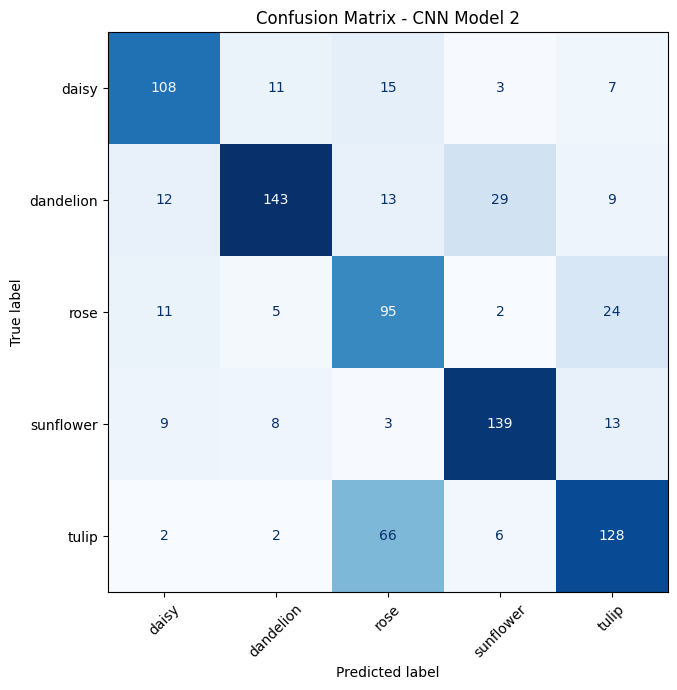

In [38]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_2,
    display_labels=validation_dataset_eval.class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=plt.gca(),
    colorbar=False
)

plt.title("Confusion Matrix - CNN Model 2")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "confusion_matrix_model_2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
